# COVID-19 Mortality Risk Model: walkthrough

I built a 30-day mortality risk model for confirmed COVID-19 patients on 3.9 million patients from Mexico's national records. Tested on 2.41 million patients from a later year (2021), it reaches ROC-AUC 0.949, and the 10% highest-risk patients include 78% of all deaths.

This notebook walks through how it was built and validated. It reads the results saved in the repository and recomputes the key metrics from the published sample of 2021 predictions. Nothing here needs the 12.7-million-row government files, so it runs in seconds.

**The decision being supported:** when a patient with confirmed COVID-19 first arrives at a health unit, which patients should be prioritised for monitoring and beds?

| Part | What it shows |
|---|---|
| 1 | Where it started: why my capstone version (v1) was rebuilt |
| 2a | Raw data, cleaning and validation, run live on real records |
| 2b | Feature engineering: from raw codes to model inputs, run live |
| 2 | Data: 3.9 million confirmed patients from Mexico's national records, plus data-quality checks |
| 3 | Exploratory analysis |
| 4 | Model screening (15 families), imbalance tests, and the chosen model |
| 5 | Validation: on 2021 patients, month by month, in every state, plus leakage and subgroup checks |
| 6 | Explanations: SHAP and adjusted odds ratios |
| 7 | Hypothesis tests and conclusions |

To regenerate every saved result from the raw data, run `notebooks/run_on_colab.ipynb` (about 1–1.5 hours).

In [1]:
import json, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.metrics import roc_auc_score, average_precision_score

ROOT = Path("..") if (Path("..") / "reports").exists() else Path("COVID19-Mortality-Risk")
if not (ROOT / "reports").exists():          # opened on its own (e.g. in Colab): fetch the repository
    subprocess.run(["git", "clone", "-q", "https://github.com/Muneera-DSA/COVID19-Mortality-Risk.git"], check=True)
R, REP, FIG = ROOT / "results", ROOT / "reports", ROOT / "reports" / "figures"
import sys, io, contextlib; sys.path.insert(0, str(ROOT / "src"))
load = lambda name: json.loads((R / f"{name}.json").read_text())
pd.set_option("display.max_colwidth", 80)
print("results available:", sorted(p.stem for p in R.glob("*.json")))

results available: ['benchmark', 'cohort_summary', 'data_quality', 'eda', 'explain', 'iecv', 'leakage', 'monitoring', 'select', 'subgroups', 'temporal']


## Part 1: audit of the original capstone notebook

The original notebook reported **82% accuracy and ROC-AUC 0.90**. Re-running its exact steps on its own data reproduces those numbers. Removing one flaw at a time shows what each flaw did. Every corrected version is scored on the same untouched 20% of real patients.

In [2]:
audit = json.loads((REP / "capstone_audit.json").read_text())
f = audit["facts"]
print(f"Rows: {f['rows']:,}   deaths: {f['deaths']:,} ({f['death_rate']:.1%})")
print(f"'Duplicate' rows dropped by the notebook: {f['exact_duplicate_rows']:,}")
for k, v in f["duplicates_by_outcome"].items():
    print(f"  {k:9s}: {v['share_with_identical_row']:.1%} share a profile with someone else (largest identical group: {v['largest_identical_group']})")
d = f["after_dropping_duplicates"]
print(f"After dropping them: {d['survivors_removed']:,} survivors but only {d['deaths_removed']:,} deaths removed -> death rate {d['death_rate']:.1%}")
print("ICU column identical to 'hospitalised' in every row:", f["icu_identical_to_hospitalised"])
print("Death rate of classification code 2 ('confirmed by committee'):", f"{f['death_rate_by_classification']['2']['rate']:.0%}")

Rows: 199,999   deaths: 41,407 (20.7%)
'Duplicate' rows dropped by the notebook: 125,590
  survivors: 86.5% share a profile with someone else (largest identical group: 552)
  deaths   : 2.9% share a profile with someone else (largest identical group: 3)
After dropping them: 124,985 survivors but only 605 deaths removed -> death rate 54.8%
ICU column identical to 'hospitalised' in every row: True
Death rate of classification code 2 ('confirmed by committee'): 100%


,step,change,ROC-AUC,PR-AUC,mean predicted risk,observed death rate
0,S0,Original notebook as published,0.901,0.910,0.526,0.548
1,S1,"Same model, scored on real patients",0.946,0.837,0.293,0.207
2,S2,Keep all patients when training,0.954,0.850,0.296,0.207
3,S3,Remove ICU / hospitalisation / intubation,0.903,0.710,0.344,0.207
4,S4,Remove SMOTE,0.904,0.716,0.205,0.207
5,S4b,Remove the death-only classification code,0.890,0.652,0.206,0.207
6,S5,"Correct coding, continuous age",0.899,0.680,0.205,0.207


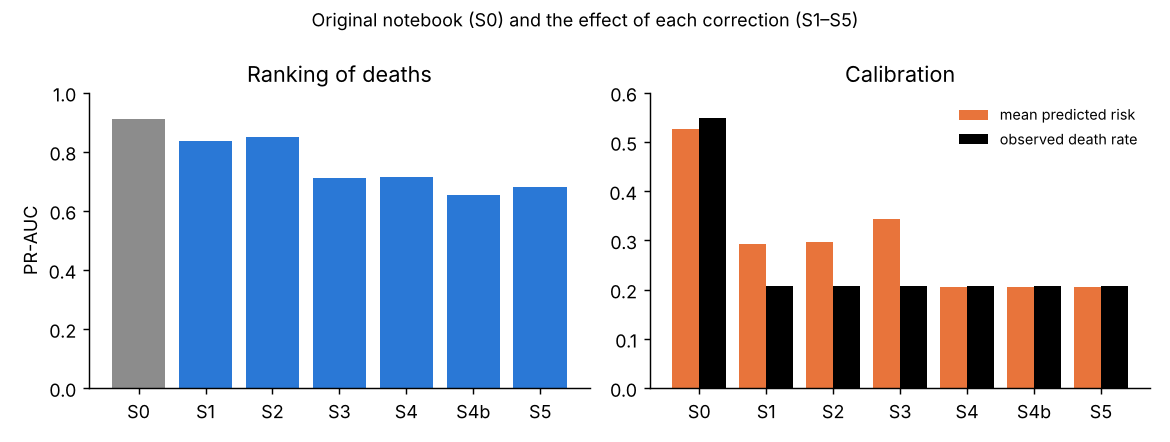

In [3]:
steps = {"S0_original_as_published": "Original notebook as published",
         "S1_original_model_on_real_patients": "Same model, scored on real patients",
         "S2_keep_all_patients": "Keep all patients when training",
         "S3_remove_post_triage_leakage": "Remove ICU / hospitalisation / intubation",
         "S4_no_smote": "Remove SMOTE",
         "S4b_remove_outcome_defined_code": "Remove the death-only classification code",
         "S5_correct_coding_and_age": "Correct coding, continuous age"}
ff = audit["flaw_by_flaw"]
flaws = pd.DataFrame([{"step": k.split("_")[0], "change": v, "ROC-AUC": ff[k]["roc_auc"], "PR-AUC": ff[k]["pr_auc"],
                       "mean predicted risk": ff[k]["mean_predicted_risk"], "observed death rate": ff[k]["death_rate"]}
                      for k, v in steps.items()]).round(3)
display(flaws)
display(Image(filename=str(FIG / "capstone_flaws.png")))

**Reading this:**
- The original ROC-AUC (S0) is reproduced. A correctly built model on the same file reaches about the same ROC-AUC (S5), so the number itself was not fake.
- The real damage is elsewhere. Trained on de-duplicated data where most patients die, the original model **over-predicts risk** on real patients (S1).
- Leaked post-triage variables inflate PR-AUC (S2 vs S3).
- SMOTE adds nothing to ranking, but distorts the predicted risk (S3 vs S4).

Part 2 rebuilds the project on the official national data.

## Part 2a: raw data, cleaning and validation (run live)

Two raw sources are stored in the repository, so every step below runs on real records:
- `data/covid_capstone.csv.gz`: the 199,999-row extract used by the original notebook;
- `data/official_sample.csv.gz`: 58,964 records in the **exact format of the official government files** (July–October 2021). This is the public sample distributed with the R package `covidmx`; the full files hold 12.7 million records.

### The capstone extract: what the codes really mean

In [4]:
cap = pd.read_csv(ROOT / "data" / "covid_capstone.csv.gz")
print(cap.shape)
display(cap.head())
codes = pd.DataFrame({c: [", ".join(map(str, sorted(cap[c].unique())[:12]))] for c in cap.columns if c not in ("AGE", "DATE_DIED")}).T
display(codes.rename(columns={0: "values found"}))

(199999, 21)


,USMER,MEDICAL_UNIT,SEX,PATIENT_TYPE,DATE_DIED,INTUBED,PNEUMONIA,AGE,PREGNANT,DIABETES,COPD,ASTHMA,INMSUPR,HIPERTENSION,OTHER_DISEASE,CARDIOVASCULAR,OBESITY,RENAL_CHRONIC,TOBACCO,CLASIFFICATION_FINAL,ICU
0,2,1,1,1,03-05-2020,3,1,65,2,0,0,0,0,1,0,0,0,0,0,3,0
1,2,1,2,1,03-06-2020,3,1,72,3,0,0,0,0,1,0,0,1,1,0,5,0
2,2,1,2,2,09-06-2020,1,2,55,3,1,0,0,0,0,0,0,0,0,0,3,1
3,2,1,1,1,12-06-2020,3,2,53,2,0,0,0,0,0,0,0,0,0,0,7,0
4,2,1,2,1,21-06-2020,3,2,68,3,1,0,0,0,1,0,0,0,0,0,3,0


,values found
USMER,"1, 2"
MEDICAL_UNIT,"1, 2, 3, 4"
SEX,"1, 2"
PATIENT_TYPE,"1, 2"
INTUBED,"1, 2, 3, 4"
PNEUMONIA,"1, 2, 99"
PREGNANT,"1, 2, 3, 4"
DIABETES,"0, 1"
COPD,"0, 1"
ASTHMA,"0, 1"


In [5]:
died = cap.DATE_DIED != "9999-99-99"
checks = [
    ("ICU is an exact copy of PATIENT_TYPE (hospitalised)", ((cap.PATIENT_TYPE - 1) == cap.ICU).all()),
    ("INTUBED code 3 marks exactly the outpatients", ((cap.INTUBED == 3) == (cap.PATIENT_TYPE == 1)).all()),
    ("PREGNANT code 3 marks exactly the men", ((cap.PREGNANT == 3) == (cap.SEX == 2)).all()),
    ("CLASIFFICATION_FINAL code 2 is given only to people who died", died[cap.CLASIFFICATION_FINAL == 2].all()),
    ("PNEUMONIA uses 99 for 'missing'", (cap.PNEUMONIA == 99).any()),
    ("all ages within 0-120", cap.AGE.between(0, 120).all()),
]
for name, ok in checks:
    print(f"{'TRUE ' if ok else 'FALSE'}  {name}")
dup = cap.drop(columns=[]).duplicated()
print(f"\nexact duplicate rows: {dup.sum():,} - of which survivors {(dup & ~died).sum():,}, deaths {(dup & died).sum():,}")
print(f"death rate: all rows {died.mean():.1%};  after dropping 'duplicates' {died[~dup].mean():.1%}")

TRUE   ICU is an exact copy of PATIENT_TYPE (hospitalised)
TRUE   INTUBED code 3 marks exactly the outpatients
TRUE   PREGNANT code 3 marks exactly the men
TRUE   CLASIFFICATION_FINAL code 2 is given only to people who died
TRUE   PNEUMONIA uses 99 for 'missing'
TRUE   all ages within 0-120

exact duplicate rows: 125,590 - of which survivors 124,985, deaths 605
death rate: all rows 20.7%;  after dropping 'duplicates' 54.8%


These checks explain the original notebook's problems. "Duplicates" are real patients with common profiles, mostly healthy survivors. `ICU` and `INTUBED` are copies of the hospitalisation decision, and code 2 can only belong to someone who died. A model must use none of them.

### The official format: cleaning and validation, using the project's own code

In [6]:
raw = pd.read_csv(ROOT / "data" / "official_sample.csv.gz", dtype=str, encoding="utf-8-sig")
print(raw.shape)
display(raw[["FECHA_INGRESO", "FECHA_SINTOMAS", "FECHA_DEF", "SEXO", "EDAD", "EMBARAZO", "DIABETES", "NEUMONIA", "TIPO_PACIENTE", "UCI", "INTUBADO", "CLASIFICACION_FINAL", "ENTIDAD_UM", "SECTOR"]].head(6))
print("CLASIFICACION_FINAL (1-3 confirmed, 4 invalid, 5 not processed, 6 suspected, 7 negative):", raw.CLASIFICACION_FINAL.value_counts().sort_index().to_dict())
print("DIABETES (1 yes, 2 no, 97 not applicable, 98 unknown, 99 not specified):", raw.DIABETES.value_counts().sort_index().to_dict())
print("FECHA_DEF placeholder for 'alive':", raw.FECHA_DEF.value_counts().index[0])

(58964, 40)


,FECHA_INGRESO,FECHA_SINTOMAS,FECHA_DEF,SEXO,EDAD,EMBARAZO,DIABETES,NEUMONIA,TIPO_PACIENTE,UCI,INTUBADO,CLASIFICACION_FINAL,ENTIDAD_UM,SECTOR
0,2021-07-08,2021-07-04,-001-11-30,1,17,2,2,2,1,97,97,7,03,12
1,2021-07-01,2021-07-01,-001-11-30,2,28,97,2,2,1,97,97,7,03,4
2,2021-07-01,2021-07-01,-001-11-30,2,30,97,2,2,1,97,97,3,03,4
3,2021-07-01,2021-07-01,-001-11-30,2,22,97,2,2,1,97,97,7,03,4
4,2021-07-01,2021-07-01,-001-11-30,2,32,97,2,2,1,97,97,7,03,6
5,2021-07-01,2021-07-01,-001-11-30,2,35,97,2,2,1,97,97,3,03,4


CLASIFICACION_FINAL (1-3 confirmed, 4 invalid, 5 not processed, 6 suspected, 7 negative): {'1': 293, '2': 9, '3': 18303, '4': 2, '5': 80, '6': 1408, '7': 38869}
DIABETES (1 yes, 2 no, 97 not applicable, 98 unknown, 99 not specified): {'1': 3979, '2': 54899, '98': 86}
FECHA_DEF placeholder for 'alive': -001-11-30


In [7]:
from covid_risk import official, features, config
with contextlib.redirect_stdout(io.StringIO()):            # hide the progress counter
    frame = official.read_file(ROOT / "data" / "official_sample.csv.gz", chunksize=20_000)
q = frame.attrs["quality"]
print(f"records read: {frame.attrs['rows_read']:,}; confirmed codes 1-3 kept: {len(frame):,}")
qual = pd.DataFrame([{"check": k.split("|", 1)[1], "type": k.split("|", 1)[0], "records": v} for k, v in q.items() if "|" in k and not k.startswith("scope")])
display(qual[qual.records > 0].sort_values("records", ascending=False))
print("(all other completeness, catalogue and consistency checks: 0 problems)")

records read: 58,964; confirmed codes 1-3 kept: 18,605


,check,type,records
3,EMBARAZO,missing,119
15,OTRA_COM,missing,73
11,INMUSUPR,missing,70
9,ASMA,missing,69
13,HIPERTENSION,missing,67
5,DIABETES,missing,66
21,RENAL_CRONICA,missing,66
7,EPOC,missing,65
17,CARDIOVASCULAR,missing,64
23,TABAQUISMO,missing,63


(all other completeness, catalogue and consistency checks: 0 problems)


In [8]:
cohort_s, flow_s = official.build_cohort([frame], frame.attrs["rows_read"])
display(pd.DataFrame(flow_s))
features.check_cohort(cohort_s)                 # raises if any rule is broken
print("check_cohort: age 0-120, binary features 0/1, outcome 0/1, no pregnant men -> all PASS")

,step,n
0,records in the yearly files,58964
1,confirmed or committee-classified (codes 1-3),18605
2,unique patients (latest version of each record),18605
3,"confirmed COVID-19 (codes 1, 3); code 2 excluded (assigned only to deaths)",18596
4,"valid age, sex and attendance date",18596
5,attended 2020-03-01..2021-11-30 with >= 30 days follow-up,18596
6,death not dated before attendance,18595


check_cohort: age 0-120, binary features 0/1, outcome 0/1, no pregnant men -> all PASS


## Part 2b: feature engineering (run live)

Only information available **when the patient first arrives** becomes a feature:

| Raw field(s) | Feature | Rule |
|---|---|---|
| `EDAD` | `age` | numeric, 0–110 kept |
| `SEXO` | `female` | 1 = woman |
| `EMBARAZO` | `pregnant` | 1 = yes; men (97) and unknown become 0 |
| 10 condition fields (`DIABETES` …) | `diabetes` … `smoking` | 1 = yes, else 0 |
| the 10 condition fields | `comorbidity_missing` | 1 if any is coded 97/98/99, so missingness is kept as information instead of being guessed |
| `NEUMONIA` | `pneumonia`, `pneumonia_missing` | yes/no, plus a missing flag |
| `FECHA_INGRESO` − `FECHA_SINTOMAS` | `days_symptoms_to_visit` | days, capped to 0–30 |
| `FECHA_DEF` − `FECHA_INGRESO` | **outcome** `died` | death within 30 days of attendance |

Excluded as predictors because they happen **after** triage: `TIPO_PACIENTE` (hospitalised), `UCI` (ICU), `INTUBADO`. `ENTIDAD_UM` (state) and `SECTOR` are used only to test generalisation and fairness, not as inputs.

In [9]:
feats = features.triage_features(cohort_s)
print("model inputs:", feats)
display(cohort_s[feats + ["died"]].head(8))
display(cohort_s[feats + ["died"]].describe().T[["mean", "std", "min", "max"]].round(3))

model inputs: ['age', 'female', 'pregnant', 'diabetes', 'copd', 'asthma', 'immunosuppression', 'hypertension', 'other_disease', 'cardiovascular', 'obesity', 'chronic_kidney', 'smoking', 'pneumonia', 'pneumonia_missing', 'comorbidity_missing', 'days_symptoms_to_visit']


,age,female,pregnant,diabetes,copd,asthma,immunosuppression,hypertension,other_disease,cardiovascular,obesity,chronic_kidney,smoking,pneumonia,pneumonia_missing,comorbidity_missing,days_symptoms_to_visit,died
0,30.0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0.0,0
1,17.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3.0,0
2,41.0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,3.0,0
3,33.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4.0,0
4,29.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2.0,0
5,25.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2.0,0
6,53.0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,2.0,0
7,39.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0


,mean,std,min,max
age,35.842,16.412,0.0,105.0
female,0.490,0.500,0.0,1.0
pregnant,0.012,0.108,0.0,1.0
diabetes,0.081,0.272,0.0,1.0
copd,0.007,0.082,0.0,1.0
asthma,0.022,0.148,0.0,1.0
immunosuppression,0.006,0.075,0.0,1.0
hypertension,0.115,0.320,0.0,1.0
other_disease,0.018,0.134,0.0,1.0
cardiovascular,0.013,0.111,0.0,1.0


30-day deaths: 859 (4.6%); deaths at any time: 903 - the 30-day window makes every patient's outcome comparable


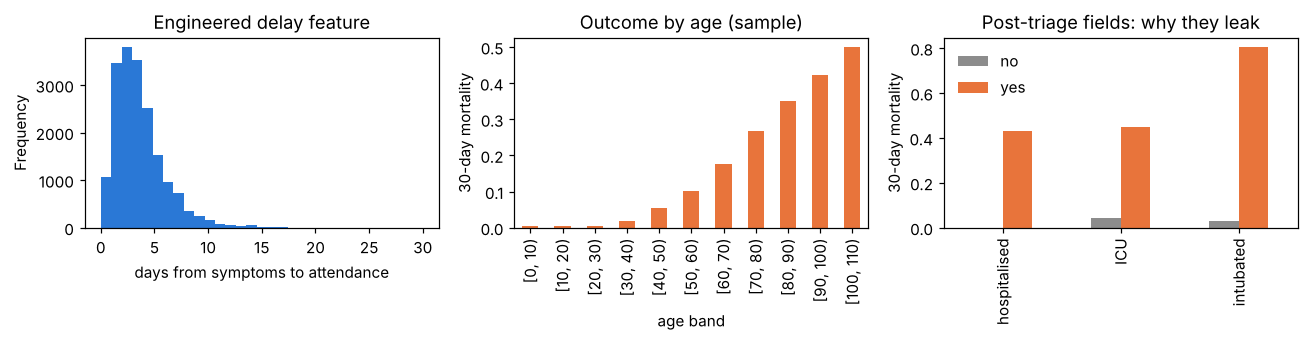

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
cohort_s.days_symptoms_to_visit.plot.hist(bins=31, ax=ax[0], color="#2a78d6")
ax[0].set(xlabel="days from symptoms to attendance", title="Engineered delay feature")
cohort_s.groupby(pd.cut(cohort_s.age, range(0, 111, 10), right=False), observed=True).died.mean().plot.bar(ax=ax[1], color="#e8743b")
ax[1].set(xlabel="age band", ylabel="30-day mortality", title="Outcome by age (sample)")
post = pd.DataFrame({"hospitalised": cohort_s.groupby("hospitalised").died.mean(), "ICU": cohort_s.groupby("icu").died.mean(),
                     "intubated": cohort_s.groupby("intubated").died.mean()}).T
post.plot.bar(ax=ax[2], color=["#8c8c8c", "#e8743b"]); ax[2].set(ylabel="30-day mortality", title="Post-triage fields: why they leak")
ax[2].legend(["no", "yes"], frameon=False)
plt.tight_layout(); plt.show()
print(f"30-day deaths: {cohort_s.died.sum():,} ({cohort_s.died.mean():.1%}); deaths at any time: {cohort_s.died_any_time.sum():,} - "
      f"the 30-day window makes every patient's outcome comparable")

Patients who were intubated or sent to ICU die far more often. A model allowed to see those fields would look excellent, but it would only be detecting decisions doctors had already made. The leakage check in Part 5 measures that effect on the national data.

## Part 2: the national data (3.9 million patients) and its quality

In [11]:
cohort = load("cohort_summary")
display(pd.DataFrame(cohort["flow"]).rename(columns={"step": "cohort step", "n": "patients"}))
periods = pd.DataFrame(cohort["periods"]).T[["patients", "deaths_30d", "death_rate_30d", "attended_from", "attended_to", "age_median", "pneumonia", "hospitalised"]]
display(periods)

,cohort step,patients
0,records in the yearly files,12698741
1,confirmed or committee-classified (codes 1-3),4089784
2,unique patients (latest version of each record),4089784
3,"confirmed COVID-19 (codes 1, 3); code 2 excluded (assigned only to deaths)",4074247
4,"valid age, sex and attendance date",4073940
5,attended 2020-03-01..2021-11-30 with >= 30 days follow-up,3922608
6,death not dated before attendance,3922386


,patients,deaths_30d,death_rate_30d,attended_from,attended_to,age_median,pneumonia,hospitalised
development,1511556,142447,0.094239,2020-03-01,2020-12-31,43.0,0.153395,0.201871
test,2410830,136306,0.056539,2021-01-01,2021-11-30,37.0,0.088576,0.122067


In [12]:
dq = load("data_quality")
print(f"Raw confirmed records checked: {dq['records_checked']:,}")
display(pd.DataFrame(dq["completeness"]).head(8).round(4))
display(pd.DataFrame(dq["checks"]).round(5))

Raw confirmed records checked: 4,089,784


,field,scope,missing,share_missing,outside_catalogue
0,INTUBADO,624571,5568,0.0089,0
1,UCI,624571,5564,0.0089,0
2,OTRA_COM,4089784,30218,0.0074,0
3,EMBARAZO,2062844,12616,0.0061,0
4,NEUMONIA,4089784,14431,0.0035,0
5,DIABETES,4089784,9971,0.0024,0
6,TABAQUISMO,4089784,9690,0.0024,0
7,INMUSUPR,4089784,9394,0.0023,0


,check,kind,records,share
0,outpatient recorded in ICU,inconsistent,0,0.00000
1,outpatient recorded as intubated,inconsistent,0,0.00000
2,male recorded as pregnant,inconsistent,0,0.00000
3,symptoms after attendance,inconsistent,1,0.00000
4,symptoms > 30 days before attendance,inconsistent,1450,0.00035
5,attendance after file date,inconsistent,0,0.00000
6,age over 110,implausible,307,0.00008


Completeness is above 99% in every field, and no code falls outside the official catalogue. The cross-field checks (outpatients in ICU, pregnant men) find no contradictions. A few implausible ages and dates are found and handled.

Next, how the 2021 test patients differ from the 2020 training patients (standardised mean difference; |SMD| > 0.1 is a notable shift):

In [13]:
drift = pd.DataFrame(dq["drift_2020_to_2021"]).round(3)
display(drift.head(8))

,feature,development,test,smd
0,age,43.765,39.308,-0.261
1,pneumonia,0.153,0.089,-0.200
2,days_symptoms_to_visit,4.078,3.459,-0.196
3,obesity,0.155,0.099,-0.170
4,hypertension,0.178,0.120,-0.165
5,diabetes,0.138,0.092,-0.146
6,died,0.094,0.057,-0.143
7,pneumonia_missing,0.000,0.006,0.106


## Part 3: exploratory analysis

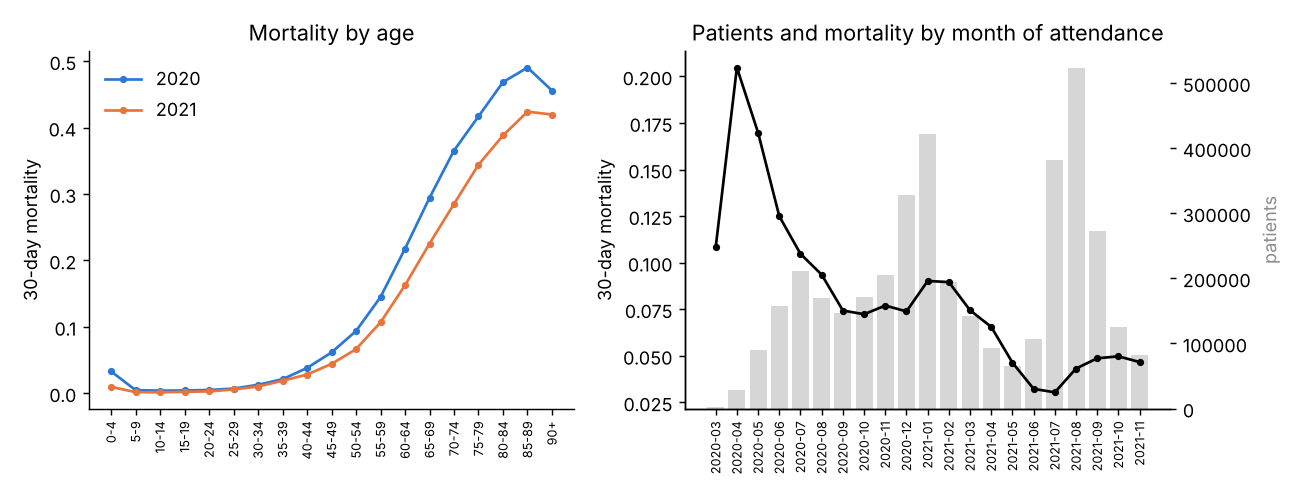

,feature,prevalence,death_rate_with,death_rate_without,crude_odds_ratio,median_age_with
10,pneumonia,0.153,0.451,0.030,26.853,58.0
8,chronic_kidney,0.016,0.416,0.089,7.283,58.0
1,copd,0.012,0.366,0.091,5.772,67.0
0,diabetes,0.138,0.261,0.068,4.869,58.0
4,hypertension,0.178,0.240,0.063,4.747,59.0
6,cardiovascular,0.017,0.291,0.091,4.115,62.0
5,other_disease,0.020,0.239,0.091,3.125,50.0
3,immunosuppression,0.009,0.241,0.093,3.099,52.0
7,obesity,0.155,0.139,0.086,1.721,46.0
9,smoking,0.075,0.099,0.094,1.066,40.0


In [14]:
display(Image(filename=str(FIG / "eda_age_month.png")))
eda = load("eda")
cond = pd.DataFrame(eda["conditions"])[["feature", "prevalence", "death_rate_with", "death_rate_without", "crude_odds_ratio", "median_age_with"]]
display(cond.sort_values("crude_odds_ratio", ascending=False).round(3))

Mortality rises steeply with age, and every condition looks dangerous **before adjustment**. But patients with these conditions are much older (see the median age column), so crude odds ratios mix the effect of the condition with the effect of age. The adjusted odds ratios in Part 6 separate the two.

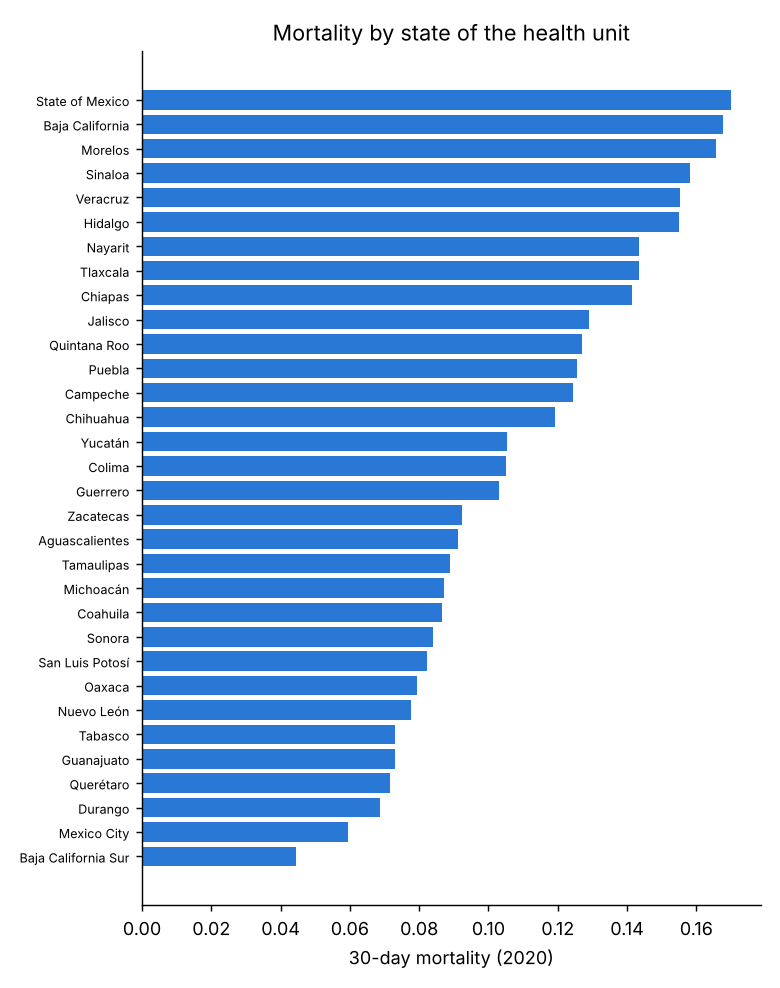

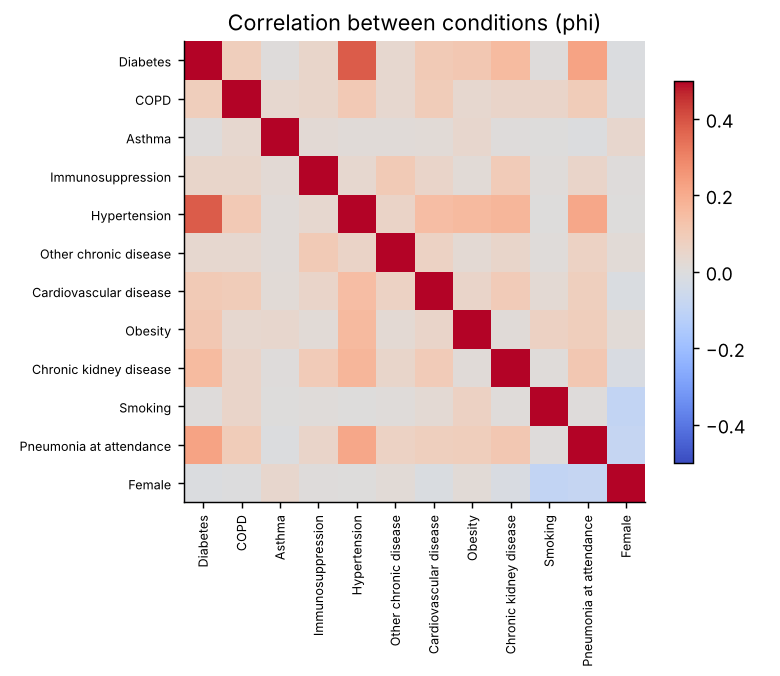

largest correlation between two conditions: |phi| = 0.38 (no problematic multicollinearity)


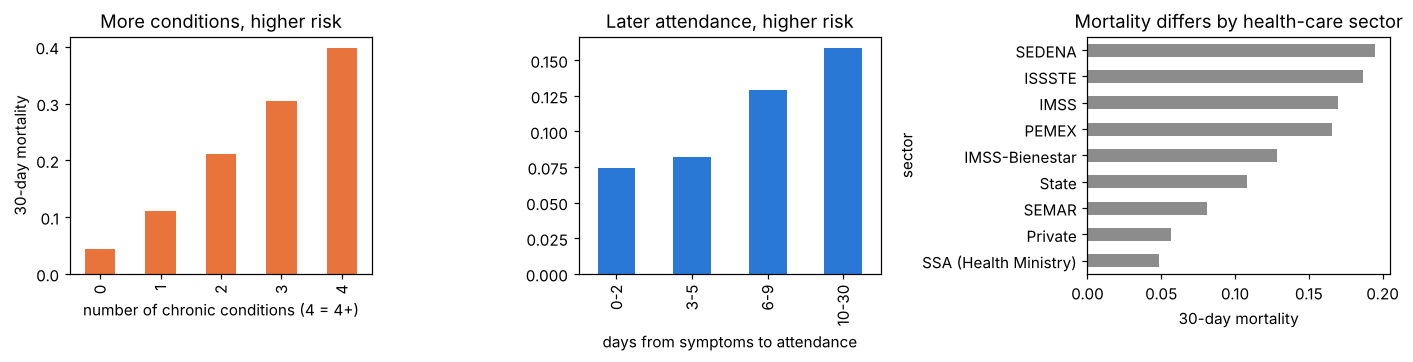

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
nc = pd.DataFrame(eda["n_conditions"]).T
nc["death_rate"].plot.bar(ax=ax[0], color="#e8743b"); ax[0].set(xlabel="number of chronic conditions (4 = 4+)", ylabel="30-day mortality", title="More conditions, higher risk")
pd.Series(eda["delay_days"]["death_rate_by_delay"]).plot.bar(ax=ax[1], color="#2a78d6"); ax[1].set(xlabel="days from symptoms to attendance", title="Later attendance, higher risk")
sec = pd.DataFrame(eda["by_sector"]).query("n >= 5000").set_index("sector").death_rate.sort_values()
sec.plot.barh(ax=ax[2], color="#8c8c8c"); ax[2].set(xlabel="30-day mortality", title="Mortality differs by health-care sector")
plt.tight_layout(); plt.show()
display(Image(filename=str(FIG / "eda_states.png")))
display(Image(filename=str(FIG / "eda_correlation.png")))
print(f"largest correlation between two conditions: |phi| = {eda['correlation']['max_abs_offdiag']:.2f} (no problematic multicollinearity)")

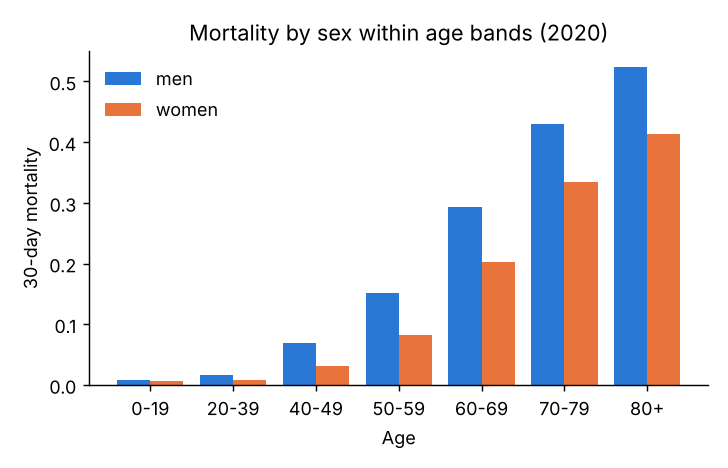

,age_band,hospitalised,icu,intubated,died
0,0-19,0.065,0.010,0.007,0.007
1,20-39,0.064,0.005,0.006,0.012
2,40-49,0.156,0.013,0.020,0.050
3,50-59,0.272,0.023,0.042,0.117
4,60-69,0.446,0.040,0.079,0.251
5,70-79,0.589,0.051,0.104,0.386
6,80+,0.657,0.055,0.096,0.473


In [16]:
display(Image(filename=str(FIG / "eda_sex_age.png")))
display(pd.DataFrame(eda["care_by_age"]).round(3))

## Part 4: model screening, imbalance and model choice

LazyPredict ranks many models **on the test set**, which leaks the test set into the choice. Here, 15 model families are compared by 5-fold cross-validation **on 2020 data only**. The 2021 test set is not touched until the end.

,model,roc_auc,pr_auc,brier,seconds
0,Histogram gradient boosting,0.9275,0.5516,0.0548,9.4
1,Random forest,0.9277,0.5510,0.0550,50.7
2,Logistic regression,0.9265,0.5499,0.0556,2.1
3,LightGBM,0.9267,0.5484,0.0551,15.0
4,Neural network (MLP 32-16),0.9267,0.5460,0.0551,32.6
5,AdaBoost,0.9255,0.5441,0.1266,38.4
6,Extra trees,0.9256,0.5434,0.0556,45.0
7,XGBoost,0.9256,0.5390,0.0557,15.2
8,LDA,0.9248,0.5379,0.0736,1.9
9,Decision tree (depth 8),0.9220,0.5342,0.0557,1.2


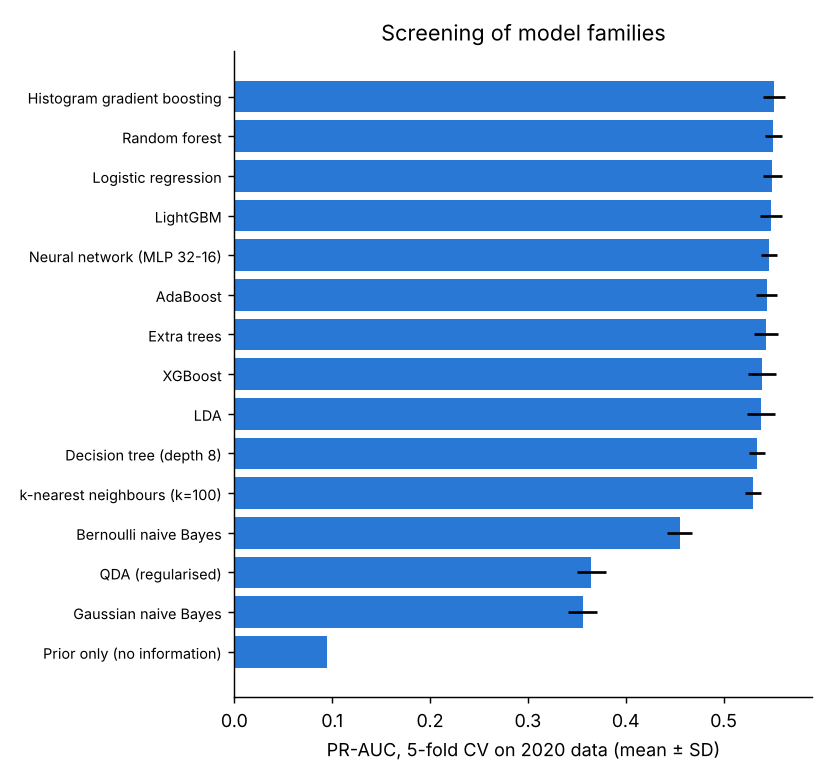

In [17]:
bench = pd.DataFrame(load("benchmark")["models"])[["model", "roc_auc", "pr_auc", "brier", "seconds"]].round(4)
display(bench)
display(Image(filename=str(FIG / "benchmark.png")))

In [18]:
sel = load("select")
cv = pd.DataFrame([{"model": k.split("|")[0], "imbalance handling": k.split("|")[1], "ROC-AUC": v["roc_auc"], "PR-AUC": v["pr_auc"],
                    "Brier": v["brier"], "calibration intercept": v["cal_intercept"]} for k, v in sel["cv"].items()]).round(4)
display(cv)
print("Chosen:", sel["choice"])

,model,imbalance handling,ROC-AUC,PR-AUC,Brier,calibration intercept
0,age_only,none,0.8434,0.3433,0.0707,0.0000
1,logistic,none,0.9279,0.5564,0.0553,-0.0005
2,logistic,class_weight,0.9285,0.5543,0.1054,-2.3725
3,logistic,oversample,0.9285,0.5542,0.1053,-2.3723
4,logistic,smote,0.9280,0.5546,0.1049,-2.3612
5,hgb,none,0.9293,0.5590,0.0544,0.0002
6,hgb,class_weight,0.9294,0.5603,0.1105,-2.2383
7,hgb,oversample,0.9289,0.5572,0.1094,-2.2354
8,hgb,smote,0.9251,0.5455,0.0826,-1.6022


Chosen: {'model': 'hgb', 'imbalance': 'none', 'params': {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 100}, 'rule': 'highest mean CV PR-AUC; imbalance correction only if significantly better than none (corrected t-test)'}


**Class imbalance:** class weights, oversampling and SMOTE do not improve PR-AUC. They push the calibration intercept far below zero: trained on 50/50 data, the model thinks death is far more common than it is. The imbalance is handled where it matters instead, by choosing a **decision threshold or capacity** (Part 5) rather than by resampling.

## Part 5: validation on 2021 patients the model never saw

In [19]:
t = load("temporal")
rows = []
for m in ("age_only", "logistic", "hgb"):
    s = t[m]
    rows.append({"model": m, "ROC-AUC": s["roc_auc"], "ROC-AUC 95% CI": tuple(round(x, 3) for x in s["roc_auc_ci"]),
                 "PR-AUC": s["pr_auc"], "Brier": s["brier"], "ECE": s["ece"],
                 "calibration intercept": s["calibration"]["intercept"], "calibration slope": s["calibration"]["slope"]})
display(pd.DataFrame(rows).round(4))
print(f"Test patients: {t['hgb']['n']:,}, deaths: {t['hgb']['deaths']:,} ({t['hgb']['death_rate']:.1%})")

,model,ROC-AUC,ROC-AUC 95% CI,PR-AUC,Brier,ECE,calibration intercept,calibration slope
0,age_only,0.8610,"(0.86, 0.862)",0.2764,0.0462,0.0171,-0.3383,0.9953
1,logistic,0.9461,"(0.946, 0.947)",0.5403,0.0340,0.0115,-0.0906,1.0957
2,hgb,0.9491,"(0.949, 0.95)",0.5458,0.0334,0.0043,-0.0487,1.0695


Test patients: 2,410,830, deaths: 136,306 (5.7%)


Recomputing the main metrics live from the published sample of 2021 predictions (200,000 patients, stratified by outcome):

In [20]:
pred = pd.read_csv(R / "test_predictions_sample.csv.gz")
y, p = pred["died"].to_numpy(), pred["p_hgb"].to_numpy()
print(f"Sample: {len(pred):,} patients, death rate {y.mean():.2%}")
print(f"ROC-AUC {roc_auc_score(y, p):.3f}   PR-AUC {average_precision_score(y, p):.3f}   mean predicted {p.mean():.2%}")
order = np.argsort(-p)
for share in (0.05, 0.10, 0.20):
    top = order[: int(share * len(p))]
    print(f"top {share:.0%} highest-risk patients contain {y[top].sum() / y.sum():.1%} of all deaths")

Sample: 200,000 patients, death rate 5.65%
ROC-AUC 0.949   PR-AUC 0.546   mean predicted 5.82%
top 5% highest-risk patients contain 52.4% of all deaths
top 10% highest-risk patients contain 78.1% of all deaths
top 20% highest-risk patients contain 92.3% of all deaths


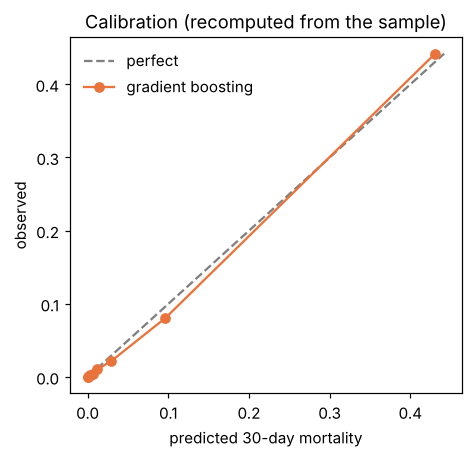

In [21]:
bins = pd.qcut(pred["p_hgb"], 10, labels=False, duplicates="drop")
cal = pred.groupby(bins).agg(predicted=("p_hgb", "mean"), observed=("died", "mean"))
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, cal.max().max()], [0, cal.max().max()], "--", color="grey", label="perfect")
ax.plot(cal.predicted, cal.observed, "o-", color="#e8743b", label="gradient boosting")
ax.set(xlabel="predicted 30-day mortality", ylabel="observed", title="Calibration (recomputed from the sample)")
ax.legend(frameon=False)
plt.show()

### Over time: ranking stays stable, calibration drifts
The model was trained on 2020 and judged month by month through 2021.

,month,n,observed,predicted,roc_auc
0,2021-01,422228,0.090,0.083,0.941
1,2021-02,194510,0.090,0.087,0.943
2,2021-03,142940,0.074,0.080,0.943
3,2021-04,93529,0.066,0.071,0.943
4,2021-05,65810,0.046,0.054,0.940
5,2021-06,107085,0.032,0.037,0.937
6,2021-07,381386,0.030,0.034,0.945
7,2021-08,522687,0.043,0.044,0.948
8,2021-09,273465,0.049,0.054,0.956
9,2021-10,124753,0.050,0.059,0.958


Rolling monthly recalibration (computed on the published stratified sample of 2021 predictions (test_predictions_sample.csv.gz)):
  calibration intercept -0.103 -> -0.031;  ECE 0.0045 -> 0.0038


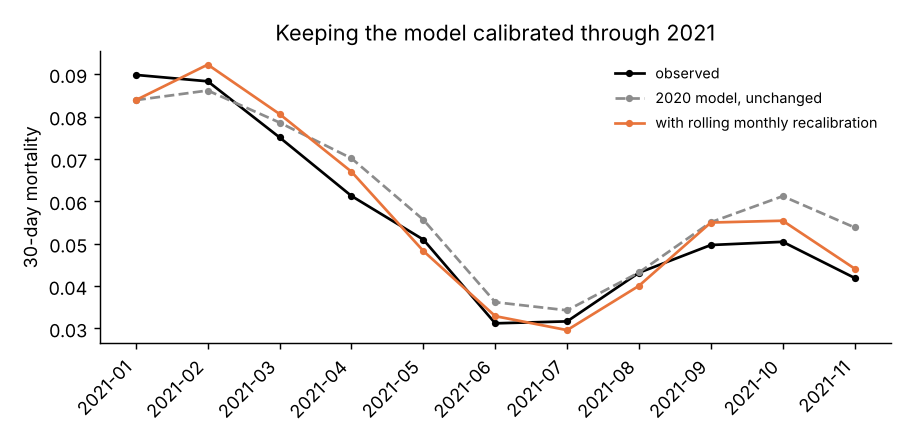

In [22]:
display(pd.DataFrame(t["monthly"]).round(3))
mon = load("monitoring")
print("Rolling monthly recalibration (computed on", mon["source"] + "):")
print(f"  calibration intercept {mon['before']['intercept']:+.3f} -> {mon['after']['intercept']:+.3f};  ECE {mon['before']['ece']:.4f} -> {mon['after']['ece']:.4f}")
display(Image(filename=str(FIG / "monitoring.png")))

A one-off correction fitted on January 2021 made calibration **worse**, because January was under-predicted while later months were over-predicted. Re-estimating the intercept every month from the previous month's outcomes helps modestly. The lesson: a deployed model needs monitoring, not a single fix.

32 states, each held out in turn: median ROC-AUC 0.927 (IQR 0.914-0.942, range 0.872-0.962); calibration intercept from -0.46 to +0.39


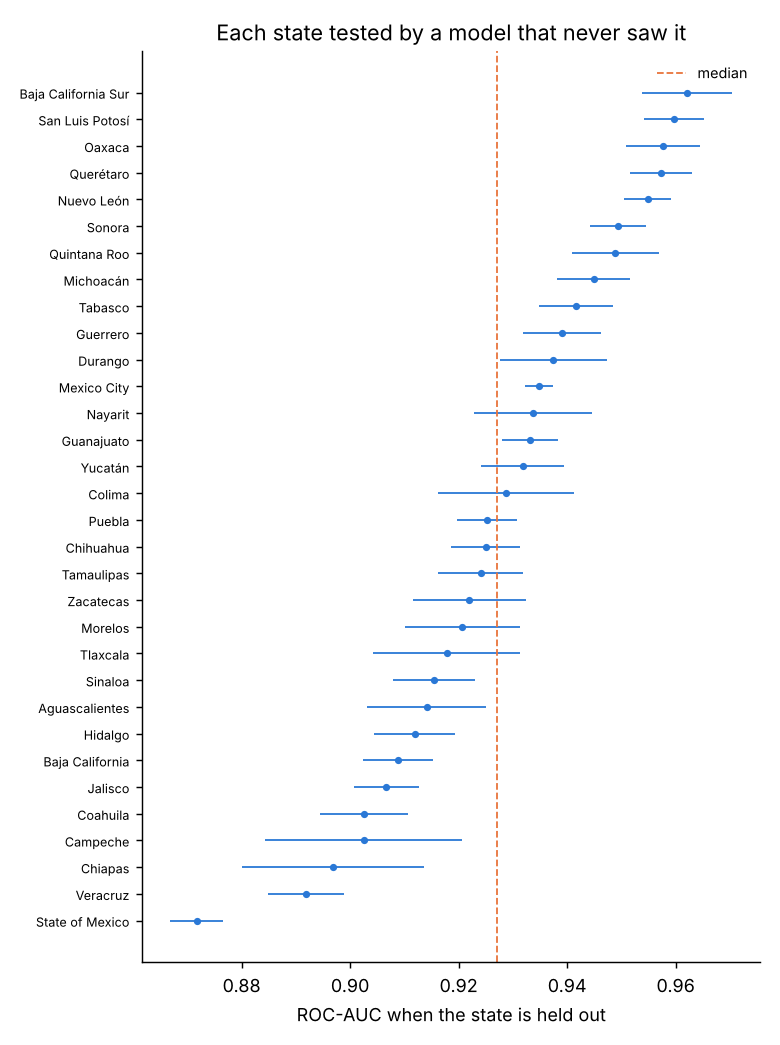

In [23]:
iv = load("iecv")
s = iv["summary"]
print(f"{s['n_states']} states, each held out in turn: median ROC-AUC {s['median_auc']:.3f} "
      f"(IQR {s['iqr_auc'][0]:.3f}-{s['iqr_auc'][1]:.3f}, range {s['min_auc']:.3f}-{s['max_auc']:.3f}); "
      f"calibration intercept from {s['range_cal_intercept'][0]:+.2f} to {s['range_cal_intercept'][1]:+.2f}")
display(Image(filename=str(FIG / "states_iecv.png")))

In [24]:
lk = load("leakage")
display(pd.DataFrame([{"features": k, "ROC-AUC": v["roc_auc"], "PR-AUC": v["pr_auc"], "ROC-AUC gain vs triage model": v["vs_triage_model"]["diff"]}
                      for k, v in lk.items()]).round(4))

,features,ROC-AUC,PR-AUC,ROC-AUC gain vs triage model
0,plus_hospitalised,0.9779,0.6241,0.0287
1,plus_all_post_triage,0.9802,0.6858,0.0310


Adding hospitalisation, ICU and intubation would make the model look much better, but those are decided **after** the triage moment. They leak the outcome, so the deployable model leaves them out.

In [25]:
sg = load("subgroups")
display(pd.DataFrame([{"group": g, **{k: r[k] for k in ("group", "n", "deaths", "observed", "predicted")}, "ROC-AUC": r.get("roc_auc")}
                      for g in ("sex", "age", "sector", "pneumonia") for r in sg[g]]).round(3))

,group,n,deaths,observed,predicted,ROC-AUC
0,female,1223002,54767,0.045,0.045,0.953
1,male,1187828,81539,0.069,0.072,0.945
2,0-39,1330454,10779,0.008,0.007,0.939
3,40-59,753370,42263,0.056,0.055,0.906
4,60-79,281574,64907,0.231,0.247,0.845
5,80+,45432,18357,0.404,0.434,0.780
6,IMSS,1063870,72805,0.068,0.055,0.945
7,ISSSTE,58766,10494,0.179,0.179,0.913
8,Other,45572,5695,0.125,0.134,0.904
9,Private,64737,2650,0.041,0.083,0.951


Within the over-80s, and among patients with pneumonia, the model ranks much less well. Most of its overall power comes from age and pneumonia, and the data lacks oxygen levels and lab results. Calibration also differs by health-care sector, so local recalibration would be needed.

## Part 6: what drives the predictions

shap.TreeExplainer 0.52.0 | completeness check, max error: 3.9218628344883655e-14


,mean |SHAP| (log-odds)
age,1.2601
pneumonia,0.7413
female,0.3450
days_symptoms_to_visit,0.1996
diabetes,0.1746
hypertension,0.1247
obesity,0.1218
smoking,0.0467
other_disease,0.0409
chronic_kidney,0.0327


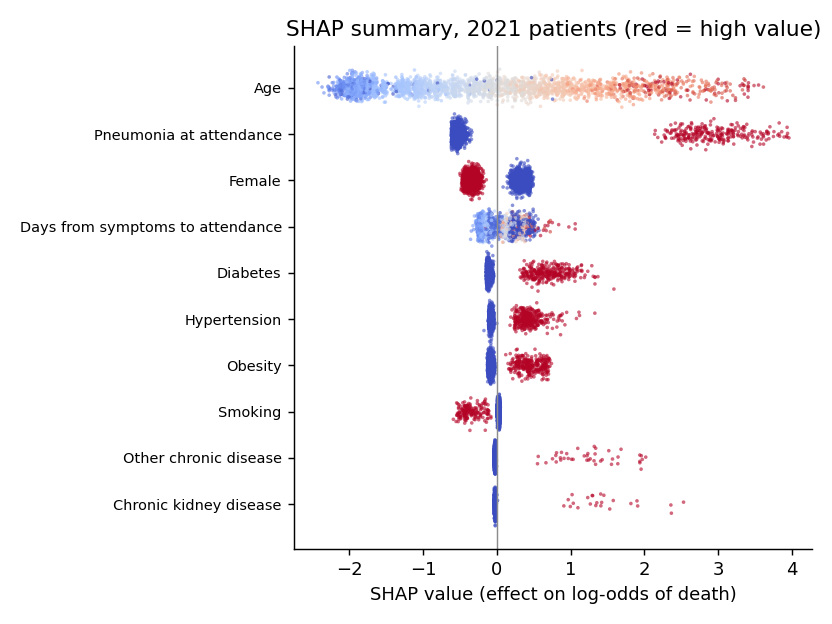

In [26]:
ex = load("explain")
print(ex["shap"]["method"], "| completeness check, max error:", ex["shap"].get("additivity_max_error"))
display(pd.Series(ex["shap"]["mean_abs"]).sort_values(ascending=False).round(4).to_frame("mean |SHAP| (log-odds)"))
display(Image(filename=str(FIG / "shap_summary.png")))

In [27]:
ors = pd.DataFrame(ex["odds_ratios"]["rows"])
ors["95% CI"] = ors["ci"].apply(lambda c: f"{c[0]:.2f}-{c[1]:.2f}")
display(ors[["feature", "odds_ratio", "95% CI", "p_holm"]].sort_values("odds_ratio", ascending=False).round(3))

,feature,odds_ratio,95% CI,p_holm
13,pneumonia,13.231,12.72-13.76,0.000
11,chronic_kidney,2.786,2.53-3.07,0.000
0,age (per 10 years),1.842,1.82-1.87,0.000
8,other_disease,1.745,1.58-1.93,0.000
3,diabetes,1.541,1.47-1.61,0.000
15,comorbidity_missing,1.513,1.27-1.80,0.000
6,immunosuppression,1.423,1.23-1.64,0.000
10,obesity,1.391,1.33-1.46,0.000
7,hypertension,1.241,1.19-1.30,0.000
4,copd,1.220,1.09-1.36,0.003


After adjustment, pneumonia, chronic kidney disease, age, diabetes, obesity and hypertension raise the risk, and female sex lowers it. Smoking and asthma appear "protective". That is a known artefact of COVID surveillance data (incomplete recording in severe cases, and who gets tested), so these are associations, not causes.

## Part 7: hypothesis tests and conclusions

In [28]:
hyp = pd.DataFrame(json.loads((REP / "results.json").read_text())["hypotheses"])
display(hyp[["id", "text", "evidence", "p_holm", "verdict"]])

,id,text,evidence,p_holm,verdict
0,H1,"Triage features add to age alone (logistic vs age-only, 2021 test)",ROC-AUC +0.085 (CI +0.084 to +0.086),0.000000e+00,supported
1,H2,Gradient boosting beats logistic regression (2021 test),ROC-AUC +0.003 (CI +0.003 to +0.003),0.000000e+00,supported
2,H3a,"Class weight improves PR-AUC (gradient boosting, 5-fold CV)",PR-AUC +0.0013; calibration slope 1.01,8.180406e-01,not supported
3,H3b,"Oversample improves PR-AUC (gradient boosting, 5-fold CV)",PR-AUC -0.0018; calibration slope 0.98,8.180406e-01,not supported
4,H3c,"Smote improves PR-AUC (gradient boosting, 5-fold CV)",PR-AUC -0.0135; calibration slope 0.96,8.944984e-02,not supported
5,H4,Calibration drifts from 2020 to 2021 (calibration-in-the-large ≠ 0),intercept -0.049; predicted 5.8% vs observed 5.7%,9.507006e-45,supported
6,H5,"Post-triage variables (hospitalisation, ICU, intubation) inflate ROC-AUC",0.980 vs 0.949 (+0.031),0.000000e+00,supported
7,H6,Discrimination differs between women and men,ROC-AUC difference (F − M) +0.008,7.671992e-49,supported


**Conclusions**
1. **Strong, honest performance on later patients.** Trained on 2020 and tested on 2.4 million 2021 patients, the model ranks risk well and is well calibrated overall. The 10% highest-risk patients include most of the deaths, which is the figure a hospital can plan capacity around.
2. **Simple models are nearly as good.** Logistic regression is within a few thousandths of ROC-AUC of gradient boosting. With millions of patients, tiny differences are "significant" but not important.
3. **Ranking generalises across time and states; calibration does not.** Deployment needs monthly monitoring and local recalibration.
4. **The model is weaker within high-risk groups** (very old patients, pneumonia), where clinical judgement and richer data are essential.
5. **The original notebook's main problems were the distorted sample, the leaked variables and resampling.** Fixing them gives a model whose risk estimates can be trusted.

See `MODEL_CARD.md` for intended use, limitations and ethical considerations.